# Machine Learning – Practical Session 4
## Overfitting, data leakage and model generalization

National Higher School of Advanced Technologies – Master 1 – 2026–2027

**Rappel des notions du cours (Lecture 2) utilisées dans ce TP**

- Risque empirique (erreur d'entraînement) : $\hat{R}_D(h) = \frac{1}{n}\sum_{i=1}^{n} \ell(h(x_i), y_i)$, avec la perte quadratique $\ell(h(x_i), y_i) = (h(x_i) - y_i)^2$. Le risque espéré (erreur de généralisation) est l'erreur moyenne sur de nouvelles données.
- Sous-apprentissage (*underfitting*) : l'espace d'hypothèses est trop restrictif, les erreurs d'entraînement et de test sont toutes les deux élevées.
- Surapprentissage (*overfitting*) : le modèle apprend le bruit des données d'entraînement ; l'erreur d'entraînement est très faible mais l'erreur de test est nettement plus élevée.
- Compromis biais–variance : $\mathbb{E}[(\hat{f}(x) - f(x))^2] = \text{Bias}^2 + \text{Variance} + \text{Noise}$
- Représentation de caractéristiques : $\phi(x) = (1, x, x^2)$, le modèle $h(x) = w_0 + w_1 x + w_2 x^2$ est linéaire en ses caractéristiques transformées mais quadratique en $x$.
- Remèdes au surapprentissage : régularisation (L1 / Lasso : certains coefficients deviennent nuls ; L2 / Ridge : les gros coefficients sont rétrécis vers zéro), réduction de la complexité du modèle (par exemple profondeur maximale d'un arbre), arrêt précoce (*early stopping*) sur validation, plus de données.
- Sélection de caractéristiques : méthodes filtre (corrélation...), wrapper, embedded (Lasso, importance des arbres).
- Procédure de sélection de modèle : définir la tâche, établir un modèle de référence (*baseline*), choisir plusieurs espaces d'hypothèses, entraîner avec le même protocole, régler les hyperparamètres sur des données de validation (ou validation croisée), comparer, puis évaluer le modèle choisi sur un jeu de test indépendant.

**Définitions utilisées dans ce TP :** $\text{RMSE} = \sqrt{\hat{R}_D(h)}$ ; $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ ; écart de généralisation (*generalization gap*) $= \text{RMSE}_{test} - \text{RMSE}_{train}$.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

def find_file(name):
    """Cherche le fichier dans le dossier du notebook puis dans quelques dossiers data."""
    for folder in [".", "data", "../data", "../../data"]:
        p = Path(folder) / name
        if p.exists():
            return p
    raise FileNotFoundError(f"{name} introuvable : place-le dans le même dossier que le notebook.")

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Partie A : Inspection des données et fuites potentielles

### A.1 Chargement, dimensions, types, statistiques et valeurs manquantes

In [2]:
raw = pd.read_csv(find_file("hybrid_student_performance_1200.csv"))
print("Dimensions :", raw.shape)
raw.dtypes.to_frame("dtype").T

Dimensions : (1200, 36)


,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,revision_frequency,focus_duration,screen_time_non_study,main_distractor,study_consistency,tasks_on_time,preparation_status,career_goal_clarity,skills_developing,energy_level,stress_level,routine_rating,sleepy_during_study,sleep_hours,career_interest,online_courses,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
dtype,str,str,str,str,int64,str,str,str,str,float64,str,str,str,str,str,str,str,str,str,float64,float64,float64,str,str,str,str,str,str,str,str,str,str,str,str,str,str


In [3]:
# Conversion de timestamp en datetime (le fichier mélange deux écritures : 3/29/2026 et 03/18/2026)
try:
    raw["timestamp"] = pd.to_datetime(raw["timestamp"], format="mixed")
except (TypeError, ValueError):
    raw["timestamp"] = pd.to_datetime(raw["timestamp"])
print("Première soumission :", raw["timestamp"].min())
print("Dernière soumission :", raw["timestamp"].max())

Première soumission : 2026-03-15 01:07:00
Dernière soumission : 2026-04-14 22:27:00


In [4]:
raw.describe()

,timestamp,age,daily_productivity,energy_level,stress_level,routine_rating
count,1200,1200.0000,1166.0000,1172.0000,1165.0000,1159.0000
mean,2026-03-30 07:20:15.285000,20.8075,2.6870,3.2278,3.1519,2.1053
min,2026-03-15 01:07:00,17.0000,1.0000,1.0000,1.0000,1.0000
25%,2026-03-22 10:58:30,19.0000,2.0000,2.0000,2.0000,1.0000
50%,2026-03-30 09:05:00,21.0000,3.0000,3.0000,3.0000,2.0000
75%,2026-04-06 23:02:00,22.0000,3.0000,4.0000,4.0000,3.0000
max,2026-04-14 22:27:00,26.0000,5.0000,5.0000,5.0000,3.0000
std,NaN,2.1870,1.1788,1.1454,1.1892,0.7881


In [5]:
raw.describe(include="object").T[["count", "unique", "top", "freq"]]

,count,unique,top,freq
student_id,1200,1200,STU0001,1
year_class,1200,6,Second Year (SY),365
program_stream,1200,7,BCA,696
gender,1200,3,Male,726
cgpa_category,1200,4,7.0 – 8.4,420
academic_satisfaction,1200,5,Neutral,426
study_hours_daily,1200,3,1–2 hours,556
revision_frequency,1166,4,Rarely,438
focus_duration,1157,3,1–2 hours,525
screen_time_non_study,1177,4,More than 6 hours,635


In [6]:
miss = pd.DataFrame({"n_missing": raw.isna().sum(), "% of rows": raw.isna().mean() * 100})
miss = miss[miss["n_missing"] > 0].sort_values("% of rows", ascending=False)
print(miss)
print(f"\nLignes avec au moins une valeur manquante : {raw.isna().any(axis=1).mean() * 100:.1f} %")

                        n_missing  % of rows
events_participation           58     4.8333
sleep_hours                    55     4.5833
external_resources             45     3.7500
focus_duration                 43     3.5833
routine_rating                 41     3.4167
programming_foundation         41     3.4167
online_courses                 36     3.0000
stress_level                   35     2.9167
daily_productivity             34     2.8333
revision_frequency             34     2.8333
external_pressure              29     2.4167
energy_level                   28     2.3333
screen_time_non_study          23     1.9167

Lignes avec au moins une valeur manquante : 35.3 %


### A.2 Observations dupliquées

In [7]:
print("Doublons exacts (toutes les colonnes)        :", raw.duplicated().sum())
print("Doublons sans student_id                      :", raw.drop(columns="student_id").duplicated().sum())
print("Doublons sans student_id ni timestamp         :", raw.drop(columns=["student_id", "timestamp"]).duplicated().sum())

Doublons exacts (toutes les colonnes)        : 0
Doublons sans student_id                      : 0
Doublons sans student_id ni timestamp         : 0


Il n'y a aucun doublon dans le fichier : la partie B.2 en introduit de façon contrôlée.

### A.3 Construction de `final_cgpa` et des variables encodées

In [8]:
df = raw.copy()

cgpa_map = {"5.0 – 6.9": 5.95, "7.0 – 8.4": 7.70, "8.5 – 9.4": 8.95, "9.5 – 10.0": 9.75}
study_map = {"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 2.5}
sleep_map = {"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 8.5}
attend_map = {"Less than 50%": 40, "50% – 65%": 57.5, "66% – 75%": 70.5, "76% – 85%": 80.5, "Above 85%": 92.5}
consistency_map = {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2}
ontime_map = {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3}
revision_map = {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3}
clarity_map = {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2}

encodings = {   # nouvelle colonne : (colonne d'origine, dictionnaire)
    "final_cgpa": ("cgpa_category", cgpa_map),
    "study_hours": ("study_hours_daily", study_map),
    "sleep_hours": ("sleep_hours", sleep_map),
    "attendance_rate": ("attendance_percentage", attend_map),
    "study_consistency": ("study_consistency", consistency_map),
    "tasks_on_time": ("tasks_on_time", ontime_map),
    "assignments_on_time": ("assignments_on_time", ontime_map),
    "revision_frequency": ("revision_frequency", revision_map),
    "career_goal_clarity": ("career_goal_clarity", clarity_map),
}
for new_col, (src, mapping) in encodings.items():
    df[new_col] = raw[src].map(mapping)
    unmapped = int((raw[src].notna() & df[new_col].isna()).sum())
    assert unmapped == 0, f"{src} : {unmapped} valeurs non reconnues"

# variables construites
df["cohort_code"] = df["program_stream"] + " | " + df["year_class"]

effort_parts = pd.concat([
    df["study_hours"] / 2.5, df["attendance_rate"] / 100, df["study_consistency"] / 2,
    df["tasks_on_time"] / 3, df["assignments_on_time"] / 3, df["revision_frequency"] / 3,
], axis=1)
df["effort_index"] = effort_parts.mean(axis=1, skipna=True)     # moyenne en ignorant les valeurs manquantes de la ligne

T0 = df["timestamp"].min()                                      # première soumission
df["submission_day"] = (df["timestamp"] - T0).dt.days

print("Tous les encodages sont complets (aucune valeur non reconnue).")
print("final_cgpa manquant :", df["final_cgpa"].isna().sum(), "| effort_index manquant :", df["effort_index"].isna().sum())
df[["student_id", "final_cgpa", "study_hours", "attendance_rate", "effort_index", "submission_day", "cohort_code"]].head()

Tous les encodages sont complets (aucune valeur non reconnue).
final_cgpa manquant : 0 | effort_index manquant : 0


,student_id,final_cgpa,study_hours,attendance_rate,effort_index,submission_day,cohort_code
0,STU0001,8.9500,0.5000,92.5000,0.3542,14,BCA | Second Year (SY)
1,STU0002,8.9500,1.5000,80.5000,0.5397,14,BCA | Second Year (SY)
2,STU0003,5.9500,1.5000,40.0000,0.6667,14,BCA | Second Year (SY)
3,STU0004,8.9500,1.5000,92.5000,0.6153,14,BCA | Second Year (SY)
4,STU0005,8.9500,1.5000,80.5000,0.5397,14,BCA | Second Year (SY)


                     corr with final_cgpa
effort_index                       0.3767
attendance_rate                    0.3650
study_consistency                  0.3223
study_hours                        0.2969
daily_productivity                 0.1322
career_goal_clarity                0.1208
tasks_on_time                      0.0972
assignments_on_time                0.0755
revision_frequency                 0.0711
age                               -0.0243
submission_day                     0.0201
stress_level                       0.0194
sleep_hours                       -0.0100


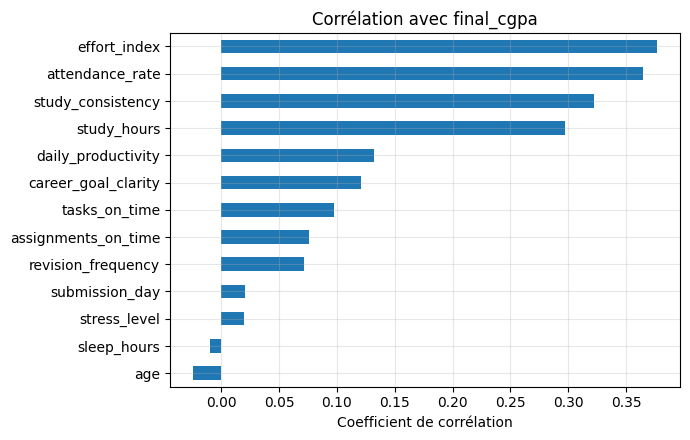

In [9]:
NUM11 = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency", "tasks_on_time",
         "assignments_on_time", "revision_frequency", "career_goal_clarity",
         "daily_productivity", "stress_level", "age"]
FEATS_B = NUM11 + ["submission_day"]            # variables de la partie B

corr = df[FEATS_B + ["effort_index", "final_cgpa"]].corr()["final_cgpa"].drop("final_cgpa")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr.to_frame("corr with final_cgpa"))

plt.figure(figsize=(7, 4.5))
corr.sort_values().plot.barh(color="tab:blue")
plt.title("Corrélation avec final_cgpa")
plt.xlabel("Coefficient de corrélation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Commentaire.** Les variables les plus corrélées à `final_cgpa` sont `effort_index` (0.3767), `attendance_rate` (0.3650), `study_consistency` (0.3223) et `study_hours` (0.2969) : plus l'effort déclaré est élevé, plus le CGPA déclaré l'est aussi. Les plus faibles sont `sleep_hours` (−0.0100), `stress_level` (0.0194), `submission_day` (0.0201) et `age` (−0.0243), pratiquement nulles. Même la meilleure corrélation reste modérée (0.38, soit environ 14 % de variance expliquée par une seule variable), ce qui annonce un $R^2$ modeste. `effort_index` est construite à partir de variables elles-mêmes corrélées à la cible, ce qui explique qu'elle arrive en tête.

### A.4 `performance_risk_level` contre `cgpa_category`

In [10]:
print(pd.crosstab(df["cgpa_category"], df["performance_risk_level"]))
print()
print(df.groupby("performance_risk_level")["final_cgpa"].agg(["count", "mean", "std"]))

# Quelle part de la variance de la cible est expliquée par la seule étiquette de risque ?
pred_by_label = df.groupby("performance_risk_level")["final_cgpa"].transform("mean")
print("\nR² d'un modèle qui prédit final_cgpa uniquement avec le niveau de risque :",
      round(r2_score(df["final_cgpa"], pred_by_label), 4))

performance_risk_level  High Risk  Low Risk  Moderate Risk
cgpa_category                                             
5.0 – 6.9                     188         0             48
7.0 – 8.4                     221         4            195
8.5 – 9.4                      39        89            234
9.5 – 10.0                      4        83             95

                        count   mean    std
performance_risk_level                     
High Risk                 452 7.0981 1.0421
Low Risk                  176 9.2989 0.4657
Moderate Risk             572 8.4050 1.0484



R² d'un modèle qui prédit final_cgpa uniquement avec le niveau de risque : 0.3956


**Commentaire.** Les deux variables sont très liées : 188 des 236 étudiants de la tranche 5.0–6.9 sont « High Risk » et aucun n'est « Low Risk », alors que 172 des 176 « Low Risk » ont un CGPA d'au moins 8.5. Le niveau de risque seul explique $R^2 = 0.3956$ de la variance de `final_cgpa`, plus que n'importe quelle variable prise isolément (la meilleure corrélation donne environ 0.14).

`performance_risk_level` ne doit **pas** être utilisée comme variable prédictive : elle semble calculée à partir des résultats de l'étudiant, c'est-à-dire de l'information que l'on cherche à prédire (fuite de la cible, *target leakage*). Elle donnerait un score élevé mais trompeur, et elle ne serait pas disponible au moment de prédire un CGPA inconnu.

### A.5 Distribution de `cohort_code`

In [11]:
cohort_counts = df["cohort_code"].value_counts()
print("Nombre de catégories :", cohort_counts.shape[0])
print("Catégories avec moins de 10 observations :", int((cohort_counts < 10).sum()))
print("Plus petite catégorie :", cohort_counts.min(), "| plus grande :", cohort_counts.max())
cohort_counts.tail(15)

Nombre de catégories : 42
Catégories avec moins de 10 observations : 12
Plus petite catégorie : 3 | plus grande : 212


cohort_code
BSc IT | First Year (PG)                  11
BA | Third Year (TY)                      11
BSc Computer Science | First Year (PG)    11
BCom | Second Year (PG)                    9
BA | First Year (PG)                       8
BA | First Year (FY)                       7
BSc Cyber Security | Second Year (PG)      7
BCom | Final Year                          6
BBA | First Year (PG)                      6
BA | Second Year (PG)                      6
BBA | Final Year                           6
BSc IT | Second Year (PG)                  5
BSc Cyber Security | Final Year            4
BBA | Second Year (PG)                     3
BA | Final Year                            3
Name: count, dtype: int64

### A.6 Ordre chronologique et dérive de `final_cgpa`

Le fichier est-il déjà trié par timestamp ? False
Après tri : True


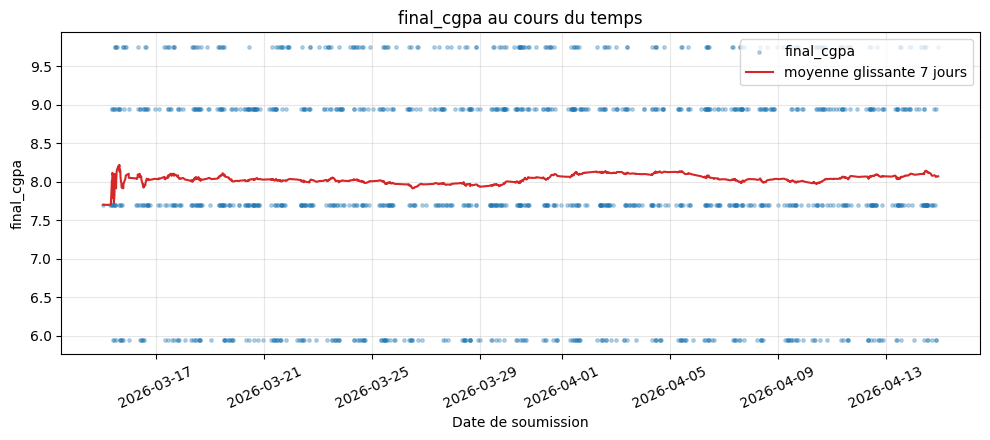

Pente de la droite final_cgpa ~ submission_day : 0.00286 point de CGPA par jour
Corrélation final_cgpa / submission_day : 0.0201
Moyenne final_cgpa, 80 % premiers : 8.0306 | 20 % derniers : 8.0967


In [12]:
print("Le fichier est-il déjà trié par timestamp ?", raw["timestamp"].is_monotonic_increasing)

df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)       # tri unique, réutilisé partout
print("Après tri :", df["timestamp"].is_monotonic_increasing)

rolling = df.set_index("timestamp")["final_cgpa"].rolling("7D").mean()
plt.figure(figsize=(10, 4.5))
plt.scatter(df["timestamp"], df["final_cgpa"], s=6, alpha=0.3, label="final_cgpa")
plt.plot(rolling.index, rolling.values, color="tab:red", label="moyenne glissante 7 jours")
plt.xlabel("Date de soumission")
plt.ylabel("final_cgpa")
plt.title("final_cgpa au cours du temps")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

slope, intercept = np.polyfit(df["submission_day"], df["final_cgpa"], 1)
print(f"Pente de la droite final_cgpa ~ submission_day : {slope:.5f} point de CGPA par jour")
print("Corrélation final_cgpa / submission_day :", round(df["final_cgpa"].corr(df["submission_day"]), 4))
n = len(df)
print("Moyenne final_cgpa, 80 % premiers :", round(df['final_cgpa'].iloc[:int(0.8*n)].mean(), 4),
      "| 20 % derniers :", round(df['final_cgpa'].iloc[int(0.8*n):].mean(), 4))

**Commentaire.** Le fichier n'est pas trié par date : il faut le trier avant toute séparation chronologique, sinon « les 80 % premiers » ne correspondent pas au passé. Après tri, la moyenne glissante sur 7 jours reste autour de 8.0 (elle fluctue seulement au tout début, quand il y a peu de points). La pente est de 0.00286 point de CGPA par jour (environ 0.09 sur les 30 jours) et la corrélation avec `submission_day` est de 0.0201 ; la moyenne passe de 8.0306 (80 % premiers) à 8.0967 (20 % derniers). Il n'y a donc **pas de tendance ni de dérive marquée** de la cible dans le temps.

**Risques identifiés dans les données (et problème de fuite ou de surapprentissage associé)**

- **Fichier non trié chronologiquement et `submission_day`** : une séparation « premiers 80 % / derniers 20 % » sans tri mélange passé et futur. Une fois trié, `submission_day` augmente avec le temps : les jours du test (24 à 30) sont à la limite ou au-delà de ceux de l'entraînement (0 à 24), et un modèle comme un arbre ne sait pas extrapoler. Risque de surapprentissage sur cette variable, alors que sa corrélation avec la cible est de 0.02.
- **`performance_risk_level`** : étiquette liée à la cible (R² de 0.3956 à elle seule). L'utiliser comme variable provoquerait une fuite de la cible et des scores artificiellement élevés.
- **Doublons potentiels** : il n'y en a pas dans ce fichier, mais dans une vraie enquête un étudiant qui soumet deux fois le formulaire peut se retrouver à la fois dans l'entraînement et dans le test (fuite étudiée en B.2).
- **`cohort_code`** : 42 catégories dont 12 ont moins de 10 observations (la plus petite en a 3). Un encodage one-hot ou un arbre peut mémoriser ces petits groupes (surapprentissage) et un encodage par la moyenne de la cible y est instable.
- **Valeurs manquantes** : 13 colonnes ont entre 1.9 % et 4.8 % de valeurs manquantes (35.3 % des lignes en ont au moins une). Si la médiane d'imputation ou la moyenne de standardisation sont calculées sur tout le jeu de données, de l'information du test fuit vers l'entraînement (B.3).
- **Cible bruitée et peu informée** : `final_cgpa` ne prend que 4 valeurs (milieux de tranches) et les corrélations sont au plus de 0.38 : un modèle trop flexible mémorise le bruit au lieu d'apprendre un motif (partie C).

# Partie B : Impact des fuites de données et de la stratégie d'évaluation

On retire `student_id` et `performance_risk_level`, et on garde les 11 variables numériques/ordinales plus `submission_day`. `cohort_code` est mise de côté jusqu'à D.1. L'imputation par la médiane est faite dans le pipeline.

In [13]:
# Séparation chronologique unique : 80 % premiers pour l'entraînement, 20 % derniers pour le test
N = len(df)
n_train = int(0.8 * N)
print(f"N = {N} | entraînement : {n_train} | test : {N - n_train}")

X_all = df[FEATS_B + ["cohort_code", "effort_index"]]
y_all = df["final_cgpa"]
X_train, X_test = X_all.iloc[:n_train], X_all.iloc[n_train:]
y_train, y_test = y_all.iloc[:n_train], y_all.iloc[n_train:]
print("Période d'entraînement :", df['timestamp'].iloc[0], "->", df['timestamp'].iloc[n_train - 1])
print("Période de test        :", df['timestamp'].iloc[n_train], "->", df['timestamp'].iloc[-1])

def tree_pipe(max_depth=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=max_depth, random_state=RANDOM_STATE)),
    ])

def baseline(X_tr, y_tr, X_te, y_te):
    """RMSE d'un modèle qui prédit toujours la moyenne de l'entraînement."""
    d = DummyRegressor(strategy="mean").fit(X_tr, y_tr)
    return rmse(y_tr, d.predict(X_tr)), rmse(y_te, d.predict(X_te))

summary_B = []   # tableau récapitulatif de la partie B

N = 1200 | entraînement : 960 | test : 240
Période d'entraînement : 2026-03-15 01:07:00 -> 2026-04-08 09:50:00
Période de test        : 2026-04-08 10:12:00 -> 2026-04-14 22:27:00


### B.1 Comparaison des stratégies de séparation (arbre de décision, `random_state=42`)

In [14]:
Xb = X_all[FEATS_B]

# (a) séparation aléatoire 80 / 20
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xb, y_all, test_size=0.2, random_state=RANDOM_STATE)
m = tree_pipe().fit(Xr_tr, yr_tr)
base_tr, base_te = baseline(Xr_tr, yr_tr, Xr_te, yr_te)
summary_B.append(["B.1 Random split", rmse(yr_tr, m.predict(Xr_tr)), rmse(yr_te, m.predict(Xr_te)), base_te])

# (b) séparation chronologique 80 / 20
m = tree_pipe().fit(X_train[FEATS_B], y_train)
base_tr, base_te = baseline(X_train[FEATS_B], y_train, X_test[FEATS_B], y_test)
summary_B.append(["B.1 Chronological split", rmse(y_train, m.predict(X_train[FEATS_B])), rmse(y_test, m.predict(X_test[FEATS_B])), base_te])

pd.DataFrame(summary_B, columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline testing RMSE"]).set_index("Strategy")

,Training RMSE,Testing RMSE,Baseline testing RMSE
Strategy,,,
B.1 Random split,0.0000,1.5420,1.3447
B.1 Chronological split,0.0000,1.9585,1.2362


In [15]:
# Vérification complémentaire : la même comparaison, sans submission_day
feats_no_day_b = [f for f in FEATS_B if f != "submission_day"]
Xr_tr2, Xr_te2, yr_tr2, yr_te2 = train_test_split(X_all[feats_no_day_b], y_all, test_size=0.2, random_state=RANDOM_STATE)
rnd = rmse(yr_te2, tree_pipe().fit(Xr_tr2, yr_tr2).predict(Xr_te2))
chr_ = rmse(y_test, tree_pipe().fit(X_train[feats_no_day_b], y_train).predict(X_test[feats_no_day_b]))
print(f"Sans submission_day : Testing RMSE random split = {rnd:.4f} | chronological split = {chr_:.4f}")
print("Plage de submission_day : entraînement", int(X_train['submission_day'].min()), "à", int(X_train['submission_day'].max()),
      "| test", int(X_test['submission_day'].min()), "à", int(X_test['submission_day'].max()))

Sans submission_day : Testing RMSE random split = 1.5710 | chronological split = 1.6377
Plage de submission_day : entraînement 0 à 24 | test 24 à 30


**Explication B.1.** L'arbre sans limite de profondeur mémorise l'entraînement (Training RMSE = 0.0000) mais son erreur de test est de 1.5420 avec la séparation aléatoire et de 1.9585 avec la séparation chronologique, soit **plus que la baseline** (1.3447 et 1.2362) dans les deux cas : c'est du surapprentissage.

L'écart entre les deux stratégies vient surtout de `submission_day` : sans cette variable, les deux erreurs de test sont proches (1.5710 contre 1.6377). Avec une séparation aléatoire, chaque ligne de test a des voisines dans le temps dans l'entraînement ; avec une séparation chronologique, tous les jours du test sont à la fin ou après la plage d'entraînement et l'arbre ne peut pas extrapoler. La séparation aléatoire donne donc ici une estimation plus **optimiste** que l'usage réel (prédire le futur à partir du passé). Les deux jeux de test sont différents, ce qui explique aussi que les baselines diffèrent.

### B.2 Fuite par doublons

On simule des étudiants qui soumettent le formulaire deux fois : 15 % des lignes (tirées avec `random_state=42`) sont dupliquées, chaque copie garde les mêmes réponses et le même `student_id` mais reçoit un nouveau timestamp aléatoire dans la période de l'enquête (`submission_day` est recalculé).

In [16]:
rng = np.random.default_rng(RANDOM_STATE)
dup_rows = df.sample(frac=0.15, random_state=RANDOM_STATE)
copies = dup_rows.copy()

start, end = df["timestamp"].min(), df["timestamp"].max()
span_seconds = (end - start).total_seconds()
copies["timestamp"] = start + pd.to_timedelta(rng.uniform(0, span_seconds, size=len(copies)), unit="s")
copies["submission_day"] = (copies["timestamp"] - T0).dt.days          # recalcul

aug = pd.concat([df, copies], ignore_index=True)
aug = aug.sort_values("timestamp", kind="stable").reset_index(drop=True)
print(f"Lignes dupliquées : {len(copies)} | taille du jeu augmenté : {len(aug)}")

Lignes dupliquées : 180 | taille du jeu augmenté : 1380


In [17]:
def split_chrono(data):
    k = int(0.8 * len(data))
    return data.iloc[:k], data.iloc[k:]

def eval_tree_on(data):
    tr, te = split_chrono(data)
    m = tree_pipe().fit(tr[FEATS_B], tr["final_cgpa"])
    _, base_te = baseline(tr[FEATS_B], tr["final_cgpa"], te[FEATS_B], te["final_cgpa"])
    n_leak = int(te["student_id"].isin(tr["student_id"]).sum())      # lignes de test dont un doublon est dans le train
    return (rmse(tr["final_cgpa"], m.predict(tr[FEATS_B])),
            rmse(te["final_cgpa"], m.predict(te[FEATS_B])), base_te, n_leak, len(tr), len(te))

# (a) séparation AVANT suppression des doublons
tr_a, te_a, base_a, leak_a, ntr_a, nte_a = eval_tree_on(aug)
summary_B.append(["B.2 Split before removing duplicates", tr_a, te_a, base_a])

# (b) suppression des doublons AVANT la séparation (toutes les colonnes sauf timestamp ; submission_day en est dérivée)
dedup_cols = [c for c in aug.columns if c not in ("timestamp", "submission_day")]
dedup = aug.drop_duplicates(subset=dedup_cols, keep="first").reset_index(drop=True)
tr_b, te_b, base_b, leak_b, ntr_b, nte_b = eval_tree_on(dedup)
summary_B.append(["B.2 Remove duplicates before split", tr_b, te_b, base_b])

print(f"(a) avant suppression : train = {ntr_a}, test = {nte_a}, lignes de test dont le doublon est dans le train = {leak_a}")
print(f"(b) après suppression : train = {ntr_b}, test = {nte_b}, lignes de test dont le doublon est dans le train = {leak_b}  (jeu de {len(dedup)} lignes)")
pd.DataFrame(summary_B[-2:], columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline testing RMSE"]).set_index("Strategy")

(a) avant suppression : train = 1104, test = 276, lignes de test dont le doublon est dans le train = 50
(b) après suppression : train = 960, test = 240, lignes de test dont le doublon est dans le train = 0  (jeu de 1200 lignes)


,Training RMSE,Testing RMSE,Baseline testing RMSE
Strategy,,,
B.2 Split before removing duplicates,0.0000,1.5758,1.2767
B.2 Remove duplicates before split,0.0000,1.6525,1.2181


**Explication B.2.** Chaque copie garde les mêmes réponses (donc la même cible) mais reçoit une date aléatoire. Comme la séparation chronologique coupe selon la date, une ligne et sa copie peuvent tomber de part et d'autre de la coupure : ici, **50 des 276 lignes du test (environ 18 %)** ont un doublon dans l'entraînement. L'arbre ayant mémorisé l'entraînement (Training RMSE = 0.0000), il retrouve exactement la bonne valeur pour ces lignes, avec une erreur nulle.

L'erreur de test semble donc meilleure quand on sépare avant de supprimer les doublons (1.5758) que lorsqu'on les supprime d'abord (1.6525) : la fuite masque une partie du surapprentissage (par rapport à la baseline, 1.23 fois contre 1.36 fois). L'effet est modéré ici parce que seulement 18 % des lignes de test sont concernées ; il serait plus fort avec plus de doublons. Après suppression des doublons, plus aucune ligne de test n'a de copie dans l'entraînement (0).

### B.3 Fuite par prétraitement (KNN, `n_neighbors=10`)

In [18]:
# (a) imputation + StandardScaler ajustés sur TOUT le jeu de données avant la séparation (fuite)
imp = SimpleImputer(strategy="median")
sc = StandardScaler()
X_leak = sc.fit_transform(imp.fit_transform(X_all[FEATS_B]))
Xl_tr, Xl_te = X_leak[:n_train], X_leak[n_train:]
knn = KNeighborsRegressor(n_neighbors=10).fit(Xl_tr, y_train)
base_te = baseline(Xl_tr, y_train, Xl_te, y_test)[1]
summary_B.append(["B.3 Scaler fitted on all data", rmse(y_train, knn.predict(Xl_tr)), rmse(y_test, knn.predict(Xl_te)), base_te])

# (b) tout est ajusté sur le train uniquement, dans un Pipeline
knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=10)),
]).fit(X_train[FEATS_B], y_train)
summary_B.append(["B.3 Scaler fitted on train only (Pipeline)",
                  rmse(y_train, knn_pipe.predict(X_train[FEATS_B])), rmse(y_test, knn_pipe.predict(X_test[FEATS_B])), base_te])

pd.DataFrame(summary_B[-2:], columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline testing RMSE"]).set_index("Strategy")

,Training RMSE,Testing RMSE,Baseline testing RMSE
Strategy,,,
B.3 Scaler fitted on all data,1.0681,1.1496,1.2362
B.3 Scaler fitted on train only (Pipeline),1.0655,1.1454,1.2362


**Explication B.3.** Les deux erreurs de test sont presque identiques (1.1496 avec la standardisation sur tout le jeu, 1.1454 avec le `Pipeline`), et la version avec fuite n'est même pas meilleure ici. L'écart est très faible parce que l'entraînement (960 lignes) et le test (240 lignes) ont des distributions proches, donc la moyenne, l'écart-type et la médiane changent à peine quand on y ajoute le test.

Le principe reste important : les statistiques de prétraitement (moyenne et écart-type du `StandardScaler`, mais aussi la médiane d'imputation) sont des paramètres **appris** à partir des données. Si elles utilisent les lignes de test, le test n'est plus complètement « inconnu » du modèle. Avec des données plus petites, des valeurs extrêmes ou un test très différent de l'entraînement, l'effet peut être beaucoup plus grand. Mettre le prétraitement dans un `Pipeline` garantit qu'il est réajusté sur l'entraînement seul à chaque fois (y compris à chaque pli de validation croisée).

### Tableau récapitulatif de la partie B

In [19]:
table_B = pd.DataFrame(summary_B, columns=["Strategy", "Training RMSE", "Testing RMSE", "Baseline testing RMSE"]).set_index("Strategy")
table_B

,Training RMSE,Testing RMSE,Baseline testing RMSE
Strategy,,,
B.1 Random split,0.0000,1.5420,1.3447
B.1 Chronological split,0.0000,1.9585,1.2362
B.2 Split before removing duplicates,0.0000,1.5758,1.2767
B.2 Remove duplicates before split,0.0000,1.6525,1.2181
B.3 Scaler fitted on all data,1.0681,1.1496,1.2362
B.3 Scaler fitted on train only (Pipeline),1.0655,1.1454,1.2362


# Partie C : Comprendre et diagnostiquer le surapprentissage

On utilise les ensembles d'entraînement et de test chronologiques de la partie B.

### C.1 Effet de la complexité du modèle (arbre de décision)

In [20]:
depths = [1, 2, 3, 5, 10, 20, None]
rows = []
for d in depths:
    m = tree_pipe(d).fit(X_train[FEATS_B], y_train)
    tr = rmse(y_train, m.predict(X_train[FEATS_B]))
    te = rmse(y_test, m.predict(X_test[FEATS_B]))
    rows.append({"max_depth": "None" if d is None else d, "Training RMSE": tr, "Testing RMSE": te, "Generalization gap": te - tr})
table_C1 = pd.DataFrame(rows).set_index("max_depth")
base_tr_c, base_te_c = baseline(X_train[FEATS_B], y_train, X_test[FEATS_B], y_test)
print(f"Baseline (moyenne du train) : RMSE train = {base_tr_c:.4f} | RMSE test = {base_te_c:.4f}")
table_C1

Baseline (moyenne du train) : RMSE train = 1.2685 | RMSE test = 1.2362


,Training RMSE,Testing RMSE,Generalization gap
max_depth,,,
1,1.1794,1.1594,-0.0200
2,1.1394,1.1268,-0.0126
3,1.1021,1.0677,-0.0344
5,1.0102,1.2905,0.2803
10,0.5314,1.9132,1.3818
20,0.0000,1.9585,1.9585
None,0.0000,1.9585,1.9585


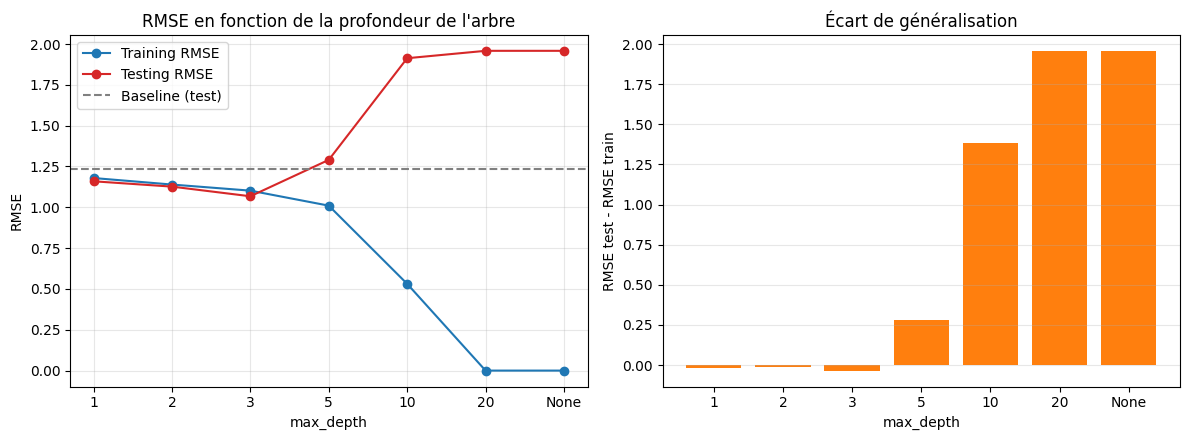

In [21]:
labels = [str(i) for i in table_C1.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(labels, table_C1["Training RMSE"], marker="o", label="Training RMSE")
axes[0].plot(labels, table_C1["Testing RMSE"], marker="o", color="tab:red", label="Testing RMSE")
axes[0].axhline(base_te_c, color="gray", linestyle="--", label="Baseline (test)")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("RMSE")
axes[0].set_title("RMSE en fonction de la profondeur de l'arbre")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(labels, table_C1["Generalization gap"], color="tab:orange")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("RMSE test - RMSE train")
axes[1].set_title("Écart de généralisation")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interprétation C.1.** Le Training RMSE diminue quand la profondeur augmente (1.1794 à profondeur 1, puis 0.0000 dès la profondeur 20), mais le Testing RMSE est minimal à la **profondeur 3** (1.0677, mieux que la baseline à 1.2362) puis remonte : 1.2905 à la profondeur 5 (déjà au-dessus de la baseline), 1.9132 à 10 et 1.9585 à 20 ou sans limite.

L'écart de généralisation devient clairement positif à partir de la **profondeur 5** (0.2803), puis explose (1.3818 à profondeur 10, 1.9585 sans limite) : **le surapprentissage commence à la profondeur 5**, quand l'erreur d'entraînement continue de baisser alors que celle de test augmente. Pour les profondeurs 1 à 3, l'écart est légèrement négatif (de −0.02 à −0.03) : l'erreur de test est un peu plus faible que celle d'entraînement parce que la période de test est ici un peu plus « facile » (la baseline vaut 1.2362 sur le test contre 1.2685 sur l'entraînement). Aux faibles profondeurs, l'arbre est très simple et gagne peu sur la baseline (1.1594 contre 1.2362 à profondeur 1) : on est proche du sous-apprentissage.

### C.2 Effet de la complexité des caractéristiques (polynômes de `effort_index`)

Pipeline `PolynomialFeatures` → `StandardScaler` → `LinearRegression`, évalué avec `TimeSeriesSplit` (5 plis) sur l'ensemble d'entraînement uniquement. Une étape d'imputation par la médiane est ajoutée en tête du pipeline par précaution.

In [22]:
tscv = TimeSeriesSplit(n_splits=5)

def poly_pipe(degree, model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

def cv_rmse(pipe, X, y):
    scores = cross_val_score(pipe, X, y, cv=tscv, scoring="neg_root_mean_squared_error")
    return -scores.mean()

X_eff_train = X_train[["effort_index"]]
degrees = [1, 2, 3, 5, 9, 15]
cv_by_degree = {d: cv_rmse(poly_pipe(d, LinearRegression()), X_eff_train, y_train) for d in degrees}
cv_baseline = cv_rmse(Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", DummyRegressor())]), X_eff_train, y_train)

table_C2 = pd.DataFrame({"CV RMSE": cv_by_degree})
table_C2.index.name = "degree"
print(f"Baseline (moyenne) : CV RMSE = {cv_baseline:.4f}")
table_C2

Baseline (moyenne) : CV RMSE = 1.2680


,CV RMSE
degree,
1,1.1774
2,1.1776
3,1.1789
5,1.1854
9,1.1883
15,1.2941


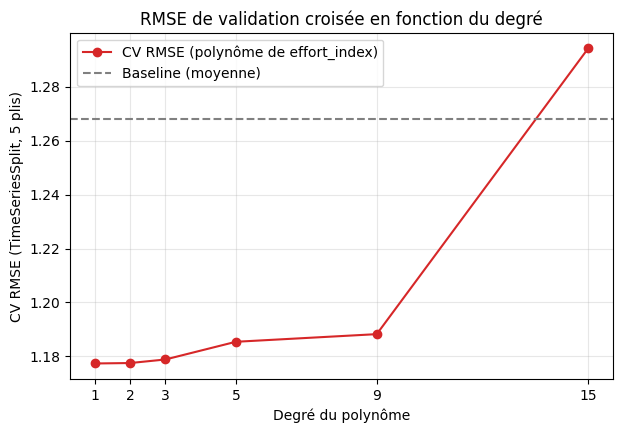

In [23]:
plt.figure(figsize=(7, 4.5))
plt.plot(list(cv_by_degree.keys()), list(cv_by_degree.values()), marker="o", color="tab:red", label="CV RMSE (polynôme de effort_index)")
plt.axhline(cv_baseline, color="gray", linestyle="--", label="Baseline (moyenne)")
plt.xticks(degrees)
plt.xlabel("Degré du polynôme")
plt.ylabel("CV RMSE (TimeSeriesSplit, 5 plis)")
plt.title("RMSE de validation croisée en fonction du degré")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interprétation C.2.** Le CV RMSE varie très peu entre les degrés 1 et 9 (de 1.1774 à 1.1883) et ne se dégrade nettement qu'au degré 15 (1.2941, au-dessus de la baseline à 1.2680). Le meilleur modèle est le degré 1 (le plus simple) ; monter en degré n'apporte aucun gain.

L'effet est **beaucoup plus petit qu'en C.1**, où l'erreur passe de 1.0677 à 1.9585. Les raisons : (i) ici il n'y a qu'**une seule variable** (`effort_index`) et un polynôme de degré 15 n'a que 16 paramètres, alors qu'un arbre sans limite crée jusqu'à 960 feuilles (une par observation) sur 11 variables ; (ii) un polynôme est une courbe lisse qui ne peut pas isoler un point bruité comme le fait un arbre ; (iii) le signal est faible (la corrélation de `effort_index` avec la cible est de 0.38), donc même le modèle linéaire fait presque aussi bien que les autres jusqu'au degré 9.

# Partie D : Amélioration de la généralisation

Dans D.1 à D.3, les options sont comparées avec le RMSE de validation (`TimeSeriesSplit`, 5 plis, sur l'ensemble d'entraînement). Le jeu de test n'est utilisé qu'en D.4.

In [24]:
def make_preprocessor(num_cols, cohort="remove", scale=False):
    """Imputation par la médiane (+ standardisation optionnelle) des variables numériques, et traitement de cohort_code."""
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    parts = [("num", Pipeline(steps), list(num_cols))]
    if cohort == "group":
        parts.append(("cohort", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False), ["cohort_code"]))
    elif cohort == "target":
        parts.append(("cohort", TargetEncoder(cv=5, shuffle=False), ["cohort_code"]))
    return ColumnTransformer(parts)

def model_pipe(estimator, num_cols, cohort="remove", scale=False):
    return Pipeline([("prep", make_preprocessor(num_cols, cohort, scale)), ("model", estimator)])

### D.1 Traitement de la variable à forte cardinalité `cohort_code` (arbre `max_depth=5`)

In [25]:
treatments = {
    "Rare-category grouping (OneHot, min_frequency=10)": "group",
    "Target encoding (out-of-fold, cv=5)": "target",
    "Feature removal": "remove",
}
rows = []
for name, mode in treatments.items():
    pipe = model_pipe(DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE), FEATS_B, cohort=mode)
    rows.append({"Treatment": name, "mode": mode, "Validation RMSE": cv_rmse(pipe, X_train, y_train)})
table_D1 = pd.DataFrame(rows).set_index("Treatment")
best_cohort = table_D1["Validation RMSE"].idxmin()
COHORT_FINAL = table_D1.loc[best_cohort, "mode"]
print("Meilleur traitement :", best_cohort)
table_D1[["Validation RMSE"]]

Meilleur traitement : Rare-category grouping (OneHot, min_frequency=10)


,Validation RMSE
Treatment,
"Rare-category grouping (OneHot, min_frequency=10)",1.2211
"Target encoding (out-of-fold, cv=5)",1.2605
Feature removal,1.2408


**Réponse D.1.** Le meilleur traitement est le **regroupement des catégories rares** (Validation RMSE 1.2211), devant la suppression de la variable (1.2408) et l'encodage par la moyenne de la cible (1.2605, le moins bon). Le regroupement ne gagne que 0.02 sur la suppression : `cohort_code` est donc **peu informative**. L'encodage par la cible est même moins bon que de retirer la variable : les moyennes calculées sur de très petits groupes (jusqu'à 3 observations) sont bruitées, et l'arbre s'ajuste à ce bruit. Par la règle choisie (meilleur RMSE de validation), on garde le regroupement des catégories rares pour la suite.

### D.2 Sélection de caractéristiques : faut-il garder `submission_day` ?

In [26]:
feats_no_day = [f for f in FEATS_B if f != "submission_day"]
estimators = {
    "Linear Regression": (LinearRegression, dict(), True),
    "Decision Tree (max_depth=5)": (DecisionTreeRegressor, dict(max_depth=5, random_state=RANDOM_STATE), False),
    "Gradient Boosting (60 trees)": (GradientBoostingRegressor, dict(n_estimators=60, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE), False),
}
rows = []
for name, (cls, params, scale) in estimators.items():
    with_day = cv_rmse(model_pipe(cls(**params), FEATS_B, COHORT_FINAL, scale), X_train, y_train)
    no_day = cv_rmse(model_pipe(cls(**params), feats_no_day, COHORT_FINAL, scale), X_train, y_train)
    rows.append({"Model": name, "With submission_day": with_day, "Without submission_day": no_day})
table_D2 = pd.DataFrame(rows).set_index("Model")
table_D2["Difference (with - without)"] = table_D2["With submission_day"] - table_D2["Without submission_day"]
table_D2

,With submission_day,Without submission_day,Difference (with - without)
Model,,,
Linear Regression,1.1393,1.1248,0.0145
Decision Tree (max_depth=5),1.2211,1.2002,0.0209
Gradient Boosting (60 trees),1.1327,1.1314,0.0013


In [27]:
# Règle de décision : on garde submission_day seulement si elle améliore (RMSE plus faible) la moyenne des trois modèles
keep_day = table_D2["With submission_day"].mean() < table_D2["Without submission_day"].mean()
FEATS_FINAL = FEATS_B if keep_day else feats_no_day
print("Garder submission_day :", keep_day)
print("Variables finales :", FEATS_FINAL)

Garder submission_day : False
Variables finales : ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age']


**Option : retirer les variables dont la corrélation avec la cible est proche de zéro (partie A, seuil |corr| < 0,05)**

In [28]:
weak = [f for f in FEATS_FINAL if abs(corr[f]) < 0.05]
feats_strong = [f for f in FEATS_FINAL if f not in weak]
print("Variables retirées (|corr| < 0.05) :", weak)

rows = []
for name, (cls, params, scale) in estimators.items():
    base_v = cv_rmse(model_pipe(cls(**params), FEATS_FINAL, COHORT_FINAL, scale), X_train, y_train)
    sel_v = cv_rmse(model_pipe(cls(**params), feats_strong, COHORT_FINAL, scale), X_train, y_train)
    rows.append({"Model": name, "All remaining features": base_v, "Without weak features": sel_v})
pd.DataFrame(rows).set_index("Model")

Variables retirées (|corr| < 0.05) : ['sleep_hours', 'stress_level', 'age']


,All remaining features,Without weak features
Model,,
Linear Regression,1.1248,1.1218
Decision Tree (max_depth=5),1.2002,1.2106
Gradient Boosting (60 trees),1.1314,1.1253


**Décision D.2.** Retirer `submission_day` améliore le RMSE de validation des trois modèles : Linear Regression 1.1393 → 1.1248, arbre 1.2211 → 1.2002, Gradient Boosting 1.1327 → 1.1314 (gain minime). On **ne garde pas** `submission_day`. Justification : sa corrélation avec la cible est de 0.02, il n'y a pas de dérive dans le temps (A.6), et avec une séparation chronologique les jours du test (24 à 30) sont à la limite ou hors de la plage d'entraînement (0 à 24), donc un modèle ne peut pas extrapoler ; la vérification de B.1 montre que cette variable explique l'essentiel de la dégradation en séparation chronologique.

**Option (retirer les variables de corrélation proche de zéro).** Les variables retirées sont `sleep_hours`, `stress_level` et `age` (|corr| < 0.05). Le RMSE de validation change peu et pas dans le même sens selon le modèle (Linear 1.1248 → 1.1218, Gradient Boosting 1.1314 → 1.1253, mais arbre 1.2002 → 1.2106) : le résultat n'est pas concluant. Une corrélation linéaire nulle n'implique pas que la variable soit inutile pour un modèle non linéaire. On garde donc les 11 variables.

### D.3 Régularisation (polynômes de degré 5 de `effort_index`)

In [29]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for a in alphas:
    rows.append({"alpha": a,
                 "Ridge": cv_rmse(poly_pipe(5, Ridge(alpha=a)), X_eff_train, y_train),
                 "Lasso": cv_rmse(poly_pipe(5, Lasso(alpha=a, max_iter=100000)), X_eff_train, y_train)})
table_D3 = pd.DataFrame(rows).set_index("alpha")
lin_cv = cv_by_degree[5]
print(f"Linear Regression (degré 5, sans pénalité) : validation RMSE = {lin_cv:.4f}")
best_ridge_alpha = table_D3["Ridge"].idxmin()
best_lasso_alpha = table_D3["Lasso"].idxmin()
print(f"Meilleur alpha Ridge : {best_ridge_alpha} (RMSE = {table_D3['Ridge'].min():.4f})")
print(f"Meilleur alpha Lasso : {best_lasso_alpha} (RMSE = {table_D3['Lasso'].min():.4f})")
table_D3

Linear Regression (degré 5, sans pénalité) : validation RMSE = 1.1854
Meilleur alpha Ridge : 10.0 (RMSE = 1.1782)
Meilleur alpha Lasso : 0.01 (RMSE = 1.1771)


,Ridge,Lasso
alpha,,
0.0010,1.1808,1.1781
0.0100,1.1800,1.1771
0.1000,1.1790,1.1772
1.0000,1.1784,1.2680
10.0000,1.1782,1.2680
100.0000,1.1805,1.2680


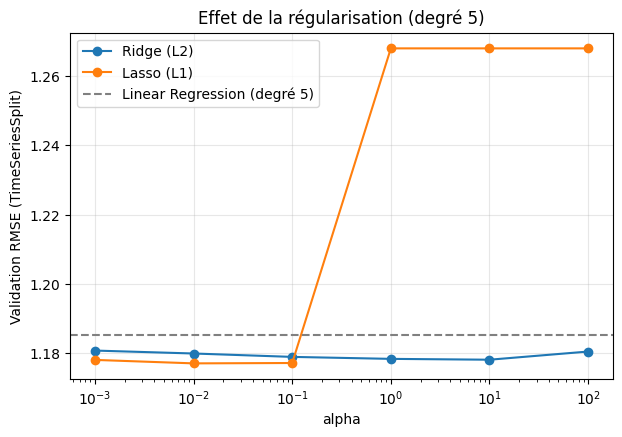

In [30]:
plt.figure(figsize=(7, 4.5))
plt.plot(table_D3.index, table_D3["Ridge"], marker="o", label="Ridge (L2)")
plt.plot(table_D3.index, table_D3["Lasso"], marker="o", label="Lasso (L1)")
plt.axhline(lin_cv, color="gray", linestyle="--", label="Linear Regression (degré 5)")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Validation RMSE (TimeSeriesSplit)")
plt.title("Effet de la régularisation (degré 5)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
# Coefficients (ajustés sur tout l'ensemble d'entraînement, avec le meilleur alpha de chaque modèle)
fits = {
    "Linear": poly_pipe(5, LinearRegression()).fit(X_eff_train, y_train),
    f"Ridge (alpha={best_ridge_alpha})": poly_pipe(5, Ridge(alpha=best_ridge_alpha)).fit(X_eff_train, y_train),
    f"Lasso (alpha={best_lasso_alpha})": poly_pipe(5, Lasso(alpha=best_lasso_alpha, max_iter=100000)).fit(X_eff_train, y_train),
}
coefs = pd.DataFrame({k: v.named_steps["model"].coef_ for k, v in fits.items()}, index=[f"x^{i}" for i in range(1, 6)])
print(coefs)
print("\nCoefficients exactement nuls :")
for k, v in fits.items():
    print(f"  {k}: {int((v.named_steps['model'].coef_ == 0).sum())} sur 5   |   somme des |coef| = {np.abs(v.named_steps['model'].coef_).sum():.4f}")

      Linear  Ridge (alpha=10.0)  Lasso (alpha=0.01)
x^1   8.8312              0.3941              0.4710
x^2 -37.7527              0.1560              0.0000
x^3  66.1826              0.0153              0.0000
x^4 -52.5146             -0.0489             -0.0000
x^5  15.7612             -0.0485             -0.0000

Coefficients exactement nuls :
  Linear: 0 sur 5   |   somme des |coef| = 181.0423
  Ridge (alpha=10.0): 0 sur 5   |   somme des |coef| = 0.6629
  Lasso (alpha=0.01): 4 sur 5   |   somme des |coef| = 0.4710


**Commentaire D.3.** La régularisation améliore légèrement le polynôme de degré 5 : Validation RMSE de 1.1854 (sans pénalité) à 1.1782 avec Ridge (meilleur α = 10) et 1.1771 avec Lasso (meilleur α = 0.01). Le gain est faible (environ 0.007 à 0.008).

Les coefficients (sur les caractéristiques polynomiales standardisées) montrent l'effet : sans pénalité, ils sont énormes et de signes alternés (8.83, −37.75, 66.18, −52.51, 15.76 ; somme des valeurs absolues = 181.04), ce qui traduit la forte colinéarité entre $x, x^2, \dots, x^5$ et un modèle très sensible aux données. Ridge les **rétrécit** tous vers zéro (somme = 0.66) sans en annuler aucun. Lasso met **4 coefficients sur 5 exactement à zéro** et ne garde que $x$ (0.4710) : il se ramène à un modèle linéaire, ce qui est cohérent avec la meilleure performance du degré 1 en C.2. Avec α ≥ 1, Lasso annule tous les coefficients et prédit simplement la moyenne (RMSE 1.2680, égal à la baseline) : une régularisation trop forte provoque du sous-apprentissage.

### D.4 Comparaison finale sur le jeu de test chronologique

Tous les modèles utilisent la même matrice de variables : celles de la partie B après les choix faits en D.1 et D.2.

In [32]:
print("Traitement de cohort_code retenu :", COHORT_FINAL)
print("Variables utilisées :", FEATS_FINAL)

# --- Ridge ou Lasso : alpha choisi par TimeSeriesSplit sur cette matrice (sans polynôme)
rl_rows = []
for kind, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        est = cls(alpha=a, max_iter=100000) if kind == "Lasso" else cls(alpha=a)
        rl_rows.append({"kind": kind, "alpha": a, "val": cv_rmse(model_pipe(est, FEATS_FINAL, COHORT_FINAL, True), X_train, y_train)})
rl = pd.DataFrame(rl_rows)
best_rl = rl.loc[rl["val"].idxmin()]
print(f"Ridge / Lasso retenu : {best_rl['kind']} avec alpha = {best_rl['alpha']} (validation RMSE = {best_rl['val']:.4f})")
rl.pivot(index="alpha", columns="kind", values="val")

Traitement de cohort_code retenu : group
Variables utilisées : ['study_hours', 'sleep_hours', 'attendance_rate', 'study_consistency', 'tasks_on_time', 'assignments_on_time', 'revision_frequency', 'career_goal_clarity', 'daily_productivity', 'stress_level', 'age']


Ridge / Lasso retenu : Lasso avec alpha = 0.1 (validation RMSE = 1.1073)


kind,Lasso,Ridge
alpha,,
0.0010,1.1234,1.1248
0.0100,1.1179,1.1248
0.1000,1.1073,1.1246
1.0000,1.2680,1.1234
10.0000,1.2680,1.1178
100.0000,1.2680,1.1136


In [33]:
# --- Arbre de décision : max_depth choisi par TimeSeriesSplit parmi les valeurs de C.1
tree_val = {d: cv_rmse(model_pipe(DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE), FEATS_FINAL, COHORT_FINAL), X_train, y_train)
            for d in [1, 2, 3, 5, 10, 20, None]}
best_depth = min(tree_val, key=tree_val.get)
print("Validation RMSE par profondeur :", {str(k): round(v, 4) for k, v in tree_val.items()})
print("max_depth retenu :", best_depth)

Validation RMSE par profondeur : {'1': np.float64(1.1799), '2': np.float64(1.162), '3': np.float64(1.1552), '5': np.float64(1.2002), '10': np.float64(1.4509), '20': np.float64(1.5481), 'None': np.float64(1.5456)}
max_depth retenu : 3


Taille du bloc d'entraînement : 816 | bloc de validation : 144
Nombre d'arbres qui minimise le RMSE de validation : 135 (RMSE = 1.0754)


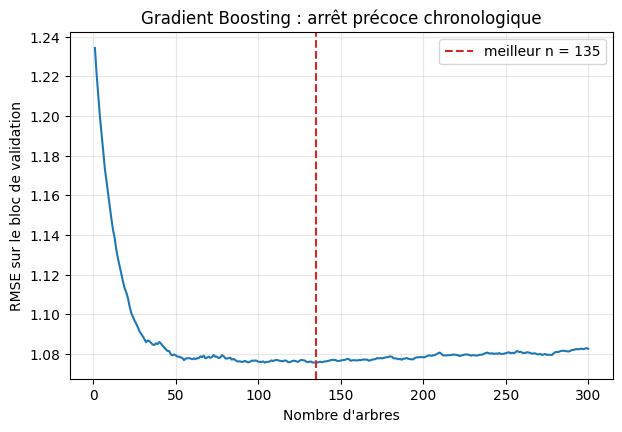

In [34]:
# --- Gradient Boosting avec arrêt précoce chronologique :
# les 15 % derniers (dans le temps) de l'entraînement servent de bloc de validation
n_fit = int(0.85 * len(X_train))
X_fit, X_val = X_train.iloc[:n_fit], X_train.iloc[n_fit:]
y_fit, y_val = y_train.iloc[:n_fit], y_train.iloc[n_fit:]

gb_search = model_pipe(
    GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
    FEATS_FINAL, COHORT_FINAL)
gb_search.fit(X_fit, y_fit)
X_val_t = gb_search[:-1].transform(X_val)
val_curve = [rmse(y_val, p) for p in gb_search.named_steps["model"].staged_predict(X_val_t)]
best_n = int(np.argmin(val_curve)) + 1
print(f"Taille du bloc d'entraînement : {n_fit} | bloc de validation : {len(X_val)}")
print(f"Nombre d'arbres qui minimise le RMSE de validation : {best_n} (RMSE = {min(val_curve):.4f})")

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(val_curve) + 1), val_curve)
plt.axvline(best_n, color="tab:red", linestyle="--", label=f"meilleur n = {best_n}")
plt.xlabel("Nombre d'arbres")
plt.ylabel("RMSE sur le bloc de validation")
plt.title("Gradient Boosting : arrêt précoce chronologique")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [35]:
# --- Réentraînement sur tout l'ensemble d'entraînement et évaluation sur le test (une seule fois)
rl_est = Ridge(alpha=best_rl["alpha"]) if best_rl["kind"] == "Ridge" else Lasso(alpha=best_rl["alpha"], max_iter=100000)
final_models = {
    "Linear Regression": model_pipe(LinearRegression(), FEATS_FINAL, COHORT_FINAL, True),
    f"{best_rl['kind']} (alpha={best_rl['alpha']})": model_pipe(rl_est, FEATS_FINAL, COHORT_FINAL, True),
    f"Decision Tree (max_depth={best_depth})": model_pipe(DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE), FEATS_FINAL, COHORT_FINAL),
    f"Gradient Boosting ({best_n} trees)": clone(gb_search).set_params(model__n_estimators=best_n),
}

d = DummyRegressor(strategy="mean").fit(X_train, y_train)
rows = [{"Model": "Baseline (training mean)",
         "Training RMSE": rmse(y_train, d.predict(X_train)),
         "Testing RMSE": rmse(y_test, d.predict(X_test)),
         "Testing R²": r2_score(y_test, d.predict(X_test))}]
for name, pipe in final_models.items():
    pipe.fit(X_train, y_train)
    rows.append({"Model": name,
                 "Training RMSE": rmse(y_train, pipe.predict(X_train)),
                 "Testing RMSE": rmse(y_test, pipe.predict(X_test)),
                 "Testing R²": r2_score(y_test, pipe.predict(X_test))})
table_D4 = pd.DataFrame(rows).set_index("Model")
table_D4["Generalization gap"] = table_D4["Testing RMSE"] - table_D4["Training RMSE"]
table_D4

,Training RMSE,Testing RMSE,Testing R²,Generalization gap
Model,,,,
Baseline (training mean),1.2685,1.2362,-0.0029,-0.0324
Linear Regression,1.0717,1.0853,0.2270,0.0136
Lasso (alpha=0.1),1.1064,1.0721,0.2457,-0.0343
Decision Tree (max_depth=3),1.1021,1.0677,0.2519,-0.0344
Gradient Boosting (135 trees),0.9554,1.0593,0.2636,0.1039


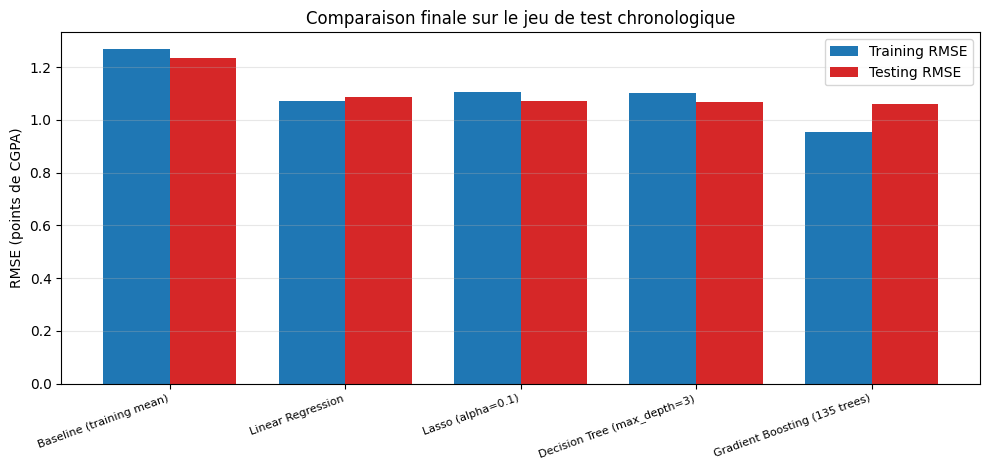

In [36]:
pos = np.arange(len(table_D4))
w = 0.38
plt.figure(figsize=(10, 4.8))
plt.bar(pos - w / 2, table_D4["Training RMSE"], w, label="Training RMSE")
plt.bar(pos + w / 2, table_D4["Testing RMSE"], w, label="Testing RMSE", color="tab:red")
plt.xticks(pos, table_D4.index, rotation=20, ha="right", fontsize=8)
plt.ylabel("RMSE (points de CGPA)")
plt.title("Comparaison finale sur le jeu de test chronologique")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Commentaire D.4.** Choix retenus (tous faits sur la validation de l'ensemble d'entraînement) : regroupement des catégories rares pour `cohort_code` (one-hot avec `min_frequency=10`), sans `submission_day` (donc les 11 autres variables plus `cohort_code` regroupée), **Lasso avec α = 0.1** (RMSE de validation 1.1073 ; le meilleur Ridge est à α = 100, bord de la grille, 1.1136), arbre de **profondeur 3** (1.1552) et Gradient Boosting avec **135 arbres** (arrêt précoce sur le dernier bloc de 15 %, RMSE 1.0754).

Sur le test, les quatre modèles battent la baseline (1.2362) mais le gain est modeste : le meilleur $R^2$ est de 0.2636 (Gradient Boosting). Les erreurs de test des modèles sont proches (de 1.0593 à 1.0853), sur seulement 240 observations. Le Gradient Boosting a le plus petit RMSE de test et le plus grand écart de généralisation (0.1039, Training RMSE 0.9554). Les écarts négatifs de la baseline, de Lasso et de l'arbre viennent, comme en C.1, du fait que la période de test est un peu plus facile que celle d'entraînement.

# Discussion finale

**1. Quel modèle généralise le mieux ?** Le Gradient Boosting avec arrêt précoce a le plus petit RMSE de test (1.0593) et le meilleur $R^2$ (0.2636), suivi de l'arbre de profondeur 3 (1.0677 ; 0.2519), de Lasso (1.0721 ; 0.2457) et de la régression linéaire (1.0853 ; 0.2270). La baseline est à 1.2362. L'écart entre ces quatre modèles est d'environ 0.026 de RMSE sur 240 observations seulement : on ne peut pas affirmer qu'il y a un vrai gagnant. En revanche, tous les modèles contrôlés battent nettement l'arbre sans limite (1.9585 en C.1).

**2. Quel modèle a le plus grand écart de généralisation ?** Parmi les modèles finaux, le Gradient Boosting (0.1039). Sur l'ensemble du TP, le plus grand écart est celui de l'arbre sans limite de profondeur (Training RMSE 0.0000, Testing RMSE 1.9585, écart 1.9585) ; pour les caractéristiques polynomiales, c'est le degré 15 (CV RMSE 1.2941, au-dessus de la baseline 1.2680).

**3. Quelles techniques ont le mieux réduit le surapprentissage ?** (i) Limiter la complexité de l'arbre : avec `max_depth=3`, l'erreur de test passe de 1.9585 (sans limite) à 1.0677 et l'écart à −0.0344. (ii) La régularisation : sur le polynôme de degré 5, la somme des valeurs absolues des coefficients passe de 181.04 à 0.66 (Ridge) et 0.47 (Lasso), et le RMSE de validation de 1.1854 à 1.1782 et 1.1771 ; sur la même matrice de variables, Lasso (1.1073) fait mieux que la régression linéaire (1.1248). (iii) L'arrêt précoce du Gradient Boosting (135 arbres). (iv) Retirer `submission_day`, qui améliore un peu les trois modèles testés. Supprimer les doublons avant la séparation et utiliser un `Pipeline` ne réduisent pas le surapprentissage, mais évitent des estimations trop optimistes.

**4. Pourquoi choisir le modèle avec la validation et non avec l'entraînement ?** L'erreur d'entraînement récompense la mémorisation : l'arbre sans limite a un Training RMSE de 0.0000 mais le pire résultat sur le test (1.9585, bien au-dessus de la baseline 1.2362). Choisir sur l'entraînement donnerait toujours le modèle le plus complexe (profondeur 20 ou sans limite, degré 15). Les données de validation n'ont pas servi à ajuster le modèle : leur erreur estime la performance sur des données nouvelles, et sélectionne la complexité qui généralise (profondeur 3, degré 1, α adapté). `TimeSeriesSplit` respecte en plus l'ordre chronologique.

**5. Pourquoi laisser le jeu de test intact pendant la sélection ?** Si on choisit le modèle ou ses hyperparamètres en regardant le score de test, le test fait partie de la procédure d'apprentissage : il n'est plus indépendant et le score final devient optimiste (biais de sélection). Il doit simuler des données réellement nouvelles. Ici, tous les choix de la partie D (traitement de `cohort_code`, `submission_day`, α, profondeur, nombre d'arbres) ont été faits sur la validation de l'ensemble d'entraînement ; le test n'est utilisé qu'une fois en D.4. Dans les parties B et C, l'énoncé demande de comparer des erreurs de test à des fins de diagnostic, sans en tirer de choix de modèle.

**6. Le meilleur $R^2$ est modeste (0.2636) : que dit-il sur l'information des variables, et pourquoi un score élevé n'est-il pas toujours bon signe ?** Seulement environ un quart de la variance du CGPA est expliqué : les variables sont des réponses déclarées en grandes tranches, la cible n'a que 4 valeurs (milieux de tranches) et la meilleure corrélation individuelle est de 0.38 (environ 14 % de variance). Une grande partie de la variation du CGPA n'est donc pas contenue dans ces variables. À l'inverse, un score élevé peut venir d'une mauvaise évaluation : l'arbre sans limite a une erreur d'entraînement nulle ($R^2 = 1$ sur l'entraînement) mais est pire que la baseline sur le test ; `performance_risk_level` seule donne $R^2 = 0.3956$, plus que tous les modèles honnêtes, parce qu'elle est liée à la cible (fuite) ; des doublons répartis entre entraînement et test ou un prétraitement ajusté sur tout le jeu de données gonflent aussi le score. Un $R^2$ modeste mesuré sur un test chronologique intact est plus fiable qu'un score élevé obtenu avec une fuite.